# Generative classifiers: assumptions, geometry, and probability quality

## 1. Introduction and learning objectives

A classifier can describe how features arise within each class and then invert that description using Bayes' rule. This gives useful inductive biases, closed-form estimators, and explicit failure modes. It also provides a small setting in which to separate a likelihood model, a posterior forecast, and a decision. A confident prediction can be mathematically consistent with a badly specified model.

By the end, explain conditional independence and covariance sharing; derive Gaussian and Naive Bayes scores; implement stable multiclass prediction and training-only text features; verify estimates and derivatives independently; and evaluate probability quality under dependence and distribution shift. This chapter's generative classifiers model labeled feature distributions. They do not generate coherent language or replace the later autoregressive-model chapters.

**Prerequisites:** Stage 00 probability, covariance, stable logarithms and linear solves; Stage 01 evaluation; [information and decisions](probability-information-and-decisions.ipynb). The [nearest-neighbor chapter](nearest-neighbors.ipynb) supplies a contrasting local inductive bias. Row-wise features have shape $(n,d)$ and integer labels shape $(n,)$. Work is CPU-only with generated arrays and tiny in-memory documents; no network downloads are needed.

## 2. Prerequisites and mathematical foundations

For classes $c\in\{1,\ldots,K\}$ define $\pi_c=P(Y=c)>0$, a feature density or mass $f_c(x)=p(x\mid Y=c)$, and the log-joint score $s_c(x)=\log\pi_c+\log f_c(x)$. Bayes' rule gives
$$p(Y=c\mid x)=\exp(s_c(x)-\operatorname{LSE}(s(x))),\qquad \operatorname{LSE}(s)=m+\log\sum_j e^{s_j-m},\quad m=\max_j s_j.$$
An additive constant shared by all class scores changes neither normalized probabilities nor the maximum-score decision. A maximum-score decision uses zero-one cost. Other costs require posterior expected risk as in the preceding information chapter. A density can exceed one: it is not a probability assigned to a single continuous point.

For a nonsingular multivariate Gaussian, $\mu_c\in\mathbb R^d$ and $\Sigma_c\in\mathbb R^{d\times d}$ is symmetric positive definite. Its log density is
$$\log f_c(x)=-\frac d2\log(2\pi)-\frac12\log\det\Sigma_c-\frac12(x-\mu_c)^T\Sigma_c^{-1}(x-\mu_c).$$
If $\Sigma_c=L_c L_c^T$ is a Cholesky factorization, solve $L_c z=x-\mu_c$, use $\|z\|^2$ for the quadratic term, and $2\sum_j\log L_{c,jj}$ for the log determinant. Do not explicitly form an inverse or a determinant followed by a logarithm. Singular Gaussian measures exist, but this ordinary full-dimensional density formula does not apply to them.

**Convention:** covariance estimates below maximize the labeled Gaussian likelihood, so their divisors are $n_c$ or $n$, not the unbiased-estimation divisors $n_c-1$ or $n-K$. A positive diagonal addition is an explicitly chosen numerical/model regularizer, not part of the unregularized MLE. Preprocessing statistics and any regularizer selection use training data and its internal validation splits only.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 02.03.01 — Separate the three probability objects

**Type:** Conceptual · **Answer:** Markdown

Explain $\pi_c$, $f_c(x)$, and $p(c\mid x)$ using a two-class sensor example. Can the most common class differ from the maximum-posterior class for one measurement? Can a high feature likelihood certify that an input is in distribution?

**Expected outcome:** three distinct definitions, a counterexample, and a limitation of likelihood-based confidence.

**Your response to Exercise 02.03.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.01**

Bayes' rule multiplies prior mass by a class-conditional density. Compare two products, not two priors alone.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.01**

The prior describes class frequency before the measurement; a class-conditional density describes measurements within a class; the posterior conditions on the observed measurement. Priors $(.9,.1)$ and densities $(.01,.5)$ give unnormalized masses $(.009,.05)$, so the minority class wins. Neither the highest class-conditional likelihood nor the largest normalized posterior certifies distributional validity. A misspecified feature model can assign high density to unrealistic inputs, and normalization compares only the listed classes. An explicit shift study or reject policy needs separate justification.

</details>

## 3. Theoretical development and worked examples

### Gaussian maximum likelihood and linear versus quadratic boundaries

For $n_c$ labeled rows in class $c$, the joint likelihood factors over observations. Maximizing the class-prior term under $\sum_c\pi_c=1$ gives $\hat\pi_c=n_c/n$. Differentiating the mean term gives $\hat\mu_c=n_c^{-1}\sum_{i:y_i=c}x_i$. With separate full covariances,
$$\hat\Sigma_c=\frac1{n_c}\sum_{i:y_i=c}(x_i-\hat\mu_c)(x_i-\hat\mu_c)^T.$$
With one covariance shared across classes, the scatter terms instead combine into
$$\hat\Sigma=\frac1n\sum_i(x_i-\hat\mu_{y_i})(x_i-\hat\mu_{y_i})^T.$$
Center within each class. The covariance of all raw rows also contains between-class separation and is a different estimator. An unrestricted covariance can be singular when a class has too few independent centered directions. Adding $\lambda I$ with declared $\lambda>0$ makes a positive-semidefinite sample covariance positive definite in exact arithmetic; extreme floating-point ranges still require diagnosis.

With shared covariance, expand the quadratic form and cancel $-x^T\Sigma^{-1}x/2$ and shared normalizers:
$$s_c'(x)=x^T\Sigma^{-1}\mu_c-\frac12\mu_c^T\Sigma^{-1}\mu_c+\log\pi_c.$$
Pairwise boundaries are affine. This is linear discriminant analysis (LDA), unrelated to the topic-model abbreviation introduced in other courses. Binary log odds have logistic form, with $w=\Sigma^{-1}(\mu_1-\mu_0)$ and $b=-\tfrac12(\mu_1^T\Sigma^{-1}\mu_1-\mu_0^T\Sigma^{-1}\mu_0)+\log(\pi_1/\pi_0)$. A logistic posterior does not imply Gaussian feature distributions, and generative and discriminative fitting need not yield the same parameters. Class-specific covariance generally retains quadratic terms: quadratic discriminant analysis (QDA). Unequal covariance does not guarantee a single simple curved separating surface in every special case.

**Hand example:** one-dimensional classes $A:\{0,2\}$ and $B:\{4,6\}$ have means $(1,5)$, priors $(1/2,1/2)$, and shared within-class variance $1$. At $x=2$, the $B$-versus-$A$ log odds are $4x-12=-4$, so $p(B\mid2)=1/(1+e^4)\approx.0179862$. The raw pooled variance around the overall mean is $5$, which would produce a different forecast. With fixed variance $v=4$ and rows $\{0,2\}$, mean negative log likelihood at $\mu=1$ is $\tfrac12\log(8\pi)+1/8$, its mean gradient is zero, and its curvature in $\mu$ is $1/4$.

### Naive Bayes as a conditional-independence model

Assume $p(x\mid c)=\prod_{j=1}^d p(x_j\mid c)$. This asserts independence **given the class**, which is stronger than zero within-class covariance outside special families and does not assert marginal independence. A diagonal Gaussian covariance gives Gaussian Naive Bayes. A shared diagonal covariance adds another restriction: equal class variances. Our diagonal mode permits class-specific variances.

For binary indicators, Bernoulli Naive Bayes uses $\theta_{cj}=P(X_j=1\mid c)$ and
$$\log f_c(x)=\sum_j[x_j\log\theta_{cj}+(1-x_j)\log(1-\theta_{cj})].$$
With a symmetric Beta$(\alpha,\alpha)$ prior, the posterior predictive probability for one feature is $(N_{cj}+\alpha)/(n_c+2\alpha)$. This is not the Beta MAP mode. Both present and absent features contribute. Treating repeated occurrences as repeated Bernoulli trials in a document changes the observation model.

For nonnegative integer word-count vectors with length $N_i=\sum_j x_{ij}$, multinomial Naive Bayes conditions on document length and uses token probabilities
$$\theta_{cj}=\frac{T_{cj}+\alpha}{\sum_\ell T_{c\ell}+d\alpha},\qquad s_c(x)=\log\pi_c+\sum_j x_j\log\theta_{cj}.$$
This is Dirichlet posterior-predictive token smoothing. The multinomial coefficient $N_i!/\prod_j x_{ij}!$ is class-independent and cancels in class posteriors; scores omitting it are not full normalized document log likelihoods. A class-dependent length model would add a term and is outside this implementation. For a whole document, plugging posterior-predictive token means into a multinomial also differs from integrating one shared uncertain token parameter over all its tokens (a Dirichlet-multinomial predictive). State this approximation.

**Hand example:** binary training rows $A:[1,0],[1,1]$, $B:[0,1],[0,1]$ and $\alpha=1$ give Bernoulli parameters $\theta_A=(3/4,1/2)$, $\theta_B=(1/4,3/4)$. For $x=[1,0]$, posterior $p(A\mid x)=6/7$. With a two-word multinomial vocabulary, class token totals $A:(3,1)$, $B:(1,3)$ and $\alpha=1$ give $(2/3,1/3)$ versus $(1/3,2/3)$. Query counts $[2,0]$ and equal priors give $p(A)=4/5$. These are different likelihood models.

### Exercise 02.03.02 — Derive the scores and a derivative

**Type:** Mathematical · **Answer:** Markdown

Derive the shared-covariance binary log odds, identifying every canceled term. For fixed positive-definite $\Sigma$ and one class, derive the mean negative-log-likelihood gradient and Hessian with respect to $\mu$. Explain why a density-normalization term may cancel for classification but still matters in density estimation.

**Expected outcome:** affine log odds; $\Sigma^{-1}(\mu-\bar x)$ and $\Sigma^{-1}$; an explicit statement of fixed covariance and averaging.

**Your response to Exercise 02.03.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.02**

Expand $(x-\mu)^T\Sigma^{-1}(x-\mu)$ and sum before differentiating the average loss.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.02**

The shared $x^T\Sigma^{-1}x$, log determinant and $d\log(2\pi)$ terms cancel between classes. The remaining coefficient of $x$ is $\Sigma^{-1}(\mu_1-\mu_0)$; the constant is the difference of mean quadratic terms plus log prior odds. Holding $\Sigma$ fixed, differentiating $\frac1{2n_c}\sum_i(x_i-\mu)^T\Sigma^{-1}(x_i-\mu)$ gives $\Sigma^{-1}(\mu-\bar x)$ and Hessian $\Sigma^{-1}$. No extra factor $n_c$ remains. A full density must integrate to one, so it needs all normalizers even when a posterior ratio cancels them. The derivative for a covariance that depends on the optimized parameter requires additional terms.

</details>

### Exercise 02.03.03 — Audit the Gaussian hand example

**Type:** Numerical · **Answer:** Markdown

Compute means, priors, shared covariance, raw pooled covariance, and $p(B\mid2)$ for the four scalar training rows. Calculate the fixed-variance NLL at $\mu=1,v=4$. Explain the effect of using an unbiased covariance in place of the MLE here.

**Expected outcome:** all hand values above, explicit covariance divisors, and a changed-model explanation.

**Your response to Exercise 02.03.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.03**

Within-class residuals are $(-1,1,-1,1)$, while residuals around the grand mean are $(-3,-1,1,3)$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.03**

Means are $1,5$, priors are $.5,.5$, shared MLE variance is $4/4=1$, and raw variance is $20/4=5$. The posterior uses log odds $-4$, giving $1/(1+e^4)\approx.0179862$. At fixed $v=4$, average squared residual is $1$, giving NLL $\frac12\log(8\pi)+1/8\approx1.737085714$. Dividing within-class scatter by $n-K=2$ instead gives variance $2$, so posterior log odds at $x=2$ become $-2$. An unbiased estimate can be useful for variance estimation, but silently substituting it changes this likelihood-fitted classifier.

</details>

### Exercise 02.03.04 — Compare discrete likelihoods and duplicated evidence

**Type:** Numerical · **Answer:** Markdown

Verify both Naive Bayes hand posteriors. For two classes with equal priors, suppose a single binary indicator has probabilities $.8$ versus $.2$. Compute the predicted posterior for observing one positive indicator and then for two perfectly duplicated positive indicators under the independence model. Explain which true observation contains new information.

**Expected outcome:** $6/7$, $4/5$, $.8$, and $16/17$, with a conditional-dependence warning.

**Your response to Exercise 02.03.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.04**

Duplicating a feature squares its likelihood ratio inside a factorized model.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.04**

The Bernoulli products are $(3/4)(1/2)=3/8$ and $(1/4)(1/4)=1/16$, hence $6/7$. The count-model ratio is $(2/3)^2:(1/3)^2=4:1$, hence $4/5$. One positive indicator gives $.8$, but the duplicated independence model gives $.8^2/(.8^2+.2^2)=16/17$. The true second indicator is deterministic given the first, so the true posterior remains $.8$. Correct classification at threshold $.5$ can coexist with deteriorated log loss and calibration. A duplicated observation is not an independent confirmation.

</details>

## 4. Guided exercises

Build one stable score-to-posterior interface first, then test each likelihood family against it. Keep units, shape checks, covariance conventions and tie behavior visible. Observed training classes are sorted; a class with no training observations is not silently added with an invented density. Maximum-score ties choose the smallest observed integer label.

### Exercise 02.03.05 — Normalize finite log-joint scores

**Type:** Programming · **Answer:** Code

Implement `posterior_from_scores(scores)` for a finite $(n,K)$ matrix, $K\ge1$. Return log posteriors and probabilities. Support an empty query matrix and do not clip finite scores. Test row-shift invariance and the equal-score case. Reject nonfinite inputs and score differences outside the representable range.

**Expected outcome:** normalized rows, accurate large-magnitude contrasts, documented error behavior, and no direct exponentiation of raw scores.

In [ ]:
# Your code for Exercise 02.03.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.05**

Subtract a row maximum, normalize the shifted exponentials, and compute log posteriors directly from shifted scores.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.05**

The log posterior remains informative even when an extremely small probability underflows to zero. We reject unrepresentable subtraction; stable normalization cannot repair every possible finite floating-point input.

~~~python
def posterior_from_scores(scores):
    scores = np.asarray(scores, dtype=float)
    if scores.ndim != 2 or scores.shape[1] == 0 or not np.isfinite(scores).all():
        raise ValueError("finite (n, K) scores with K >= 1 required")
    if len(scores) == 0:
        return scores.copy(), scores.copy()
    with np.errstate(over='raise', invalid='raise'):
        shifted = scores - scores.max(axis=1, keepdims=True)
        normalizer = np.log(np.exp(shifted).sum(axis=1, keepdims=True))
        logp = shifted - normalizer
    return logp, np.exp(logp)

demo_logp, demo_p = posterior_from_scores([[1000., 999.], [-1000., -1000.]])
assert np.allclose(demo_p.sum(axis=1), 1)
assert np.allclose(demo_p[1], [.5, .5])
~~~

</details>

### Exercise 02.03.06 — Implement a Cholesky Gaussian log density

**Type:** Programming · **Answer:** Code

Implement `gaussian_logpdf(X, mean, covariance)` without an inverse or raw determinant. Allow zero query rows, require symmetric positive-definite covariance, and check dimensions and finite values. Check the mean gradient of average NLL independently using finite differences and a separately written scalar objective.

**Expected outcome:** standard-normal and correlated-Gaussian checks, rejected singular matrices, and a derivative check with fixed covariance.

In [ ]:
# Your code for Exercise 02.03.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.06**

For row-wise residuals, solve the triangular system against the transposed residual matrix. NumPy's general solve is sufficient at this scale.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.06**

The two-dimensional solve returns shape $(d,n)$; its squared columns are Mahalanobis distances. A tiny tolerated asymmetry is explicitly symmetrized before factorization. This function reports range failure rather than silently flooring covariance eigenvalues.

~~~python
def gaussian_logpdf(X, mean, covariance):
    X = np.asarray(X, dtype=float)
    mean = np.asarray(mean, dtype=float)
    covariance = np.asarray(covariance, dtype=float)
    if X.ndim != 2 or X.shape[1] == 0 or mean.shape != (X.shape[1],):
        raise ValueError("X (n, d), mean (d,), d >= 1 required")
    d = X.shape[1]
    if covariance.shape != (d, d) or not all(np.isfinite(a).all() for a in (X, mean, covariance)):
        raise ValueError("finite compatible arrays required")
    if not np.allclose(covariance, covariance.T, rtol=1e-12, atol=1e-14):
        raise ValueError("covariance must be symmetric")
    try:
        L = np.linalg.cholesky(covariance / 2 + covariance.T / 2)
    except np.linalg.LinAlgError as error:
        raise ValueError("positive-definite covariance required") from error
    with np.errstate(over='raise', invalid='raise', divide='raise'):
        z = np.linalg.solve(L, (X - mean).T)
        values = -.5 * (d * np.log(2*np.pi) + 2*np.log(np.diag(L)).sum()
                         + np.sum(z*z, axis=0))
    if not np.isfinite(values).all():
        raise FloatingPointError("log density outside finite range")
    return values

assert np.allclose(gaussian_logpdf([[0., 0.]], [0., 0.], np.eye(2)), -np.log(2*np.pi))
~~~

</details>

## 5. Implementation challenges

Implementations are intentionally small and transparent. Full/shared covariance storage is $O(Kd^2)$ here, including replicated shared covariance for one prediction interface. Diagonal mode retains that simple storage layout; an optimized implementation can store just $Kd$ variances. Training scatter work is $O(nd^2)$ for full modes; repeated full Gaussian prediction requires covariance factorizations and solves. This is appropriate for the declared $d\le8$ experiments, not a large-vocabulary full-covariance text model.

### Exercise 02.03.07 — Fit three Gaussian covariance assumptions

**Type:** Programming · **Answer:** Code

Implement `fit_gaussian_classifier(X, labels, kind='shared', jitter=0.0)`. Modes are `shared`, `full` and class-specific `diagonal`. Return sorted classes, empirical log priors, means and covariance matrices. Validate at least two observed classes, use MLE divisors, and reject a singular result unless the caller explicitly selects adequate positive diagonal jitter. Verify that duplicating every training row leaves MLE parameters unchanged.

**Expected outcome:** hand estimates, independent scatter checks, singular-data diagnosis, and explicit numerical regularization.

In [ ]:
# Your code for Exercise 02.03.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.07**

Compute within-class residuals once. The shared covariance is the sum of class scatters divided by total observations.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.07**

This depends on `gaussian_logpdf` to check each fitted covariance. Jitter is in feature-variance units and therefore depends on feature scaling. Choosing it is a validation decision, not an automatic hidden repair.

~~~python
def fit_gaussian_classifier(X, labels, kind='shared', jitter=0.0):
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all():
        raise ValueError("finite nonempty (n, d) features required")
    if labels.shape != (len(X),) or not np.issubdtype(labels.dtype, np.integer):
        raise ValueError("one integer label per training row required")
    if kind not in ('shared', 'full', 'diagonal') or not np.isfinite(jitter) or jitter < 0:
        raise ValueError("known covariance mode and finite nonnegative jitter required")
    classes, encoded, counts = np.unique(labels, return_inverse=True, return_counts=True)
    if len(classes) < 2:
        raise ValueError("at least two observed classes required")
    with np.errstate(over='raise', invalid='raise'):
        means = np.array([X[encoded == c].mean(axis=0) for c in range(len(classes))])
        residuals = X - means[encoded]
        if kind == 'shared':
            pooled = residuals.T @ residuals / len(X)
            covariance = np.repeat(pooled[None, :, :], len(classes), axis=0)
        elif kind == 'full':
            covariance = np.array([residuals[encoded == c].T @ residuals[encoded == c] / counts[c]
                                   for c in range(len(classes))])
        else:
            covariance = np.array([np.diag(np.mean(residuals[encoded == c]**2, axis=0))
                                   for c in range(len(classes))])
        covariance += jitter * np.eye(X.shape[1])[None, :, :]
    for mean, cov in zip(means, covariance):
        gaussian_logpdf(X[:0], mean, cov)
    return dict(classes=classes, log_prior=np.log(counts / len(X)), means=means,
                covariance=covariance, kind=kind, jitter=float(jitter))

demo_gda = fit_gaussian_classifier([[0.], [2.], [4.], [6.]], [0,0,1,1])
assert np.allclose(demo_gda['covariance'], 1)
~~~

</details>

### Exercise 02.03.08 — Predict with Gaussian class models

**Type:** Programming · **Answer:** Code

Implement `predict_gaussian_classifier(model, X)` returning labels, log posteriors and probabilities in sorted-class order. Reuse stable scores and Gaussian densities. Test arbitrary integer class labels, empty queries, the scalar hand posterior, and a quadratic-versus-affine log-odds example.

**Expected outcome:** finite normalized forecasts, deterministic ties, and agreement with independently expanded discriminants.

In [ ]:
# Your code for Exercise 02.03.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.08**

Stack one log density column per class and add the log-prior vector before normalization.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.08**

This depends on `gaussian_logpdf` and `posterior_from_scores` and consumes a model made by the preceding fitter. It preserves the original integer labels. Underflowed probability entries are possible; use returned log posteriors for log loss rather than taking a new logarithm of rounded probabilities.

~~~python
def predict_gaussian_classifier(model, X):
    scores = np.column_stack([gaussian_logpdf(X, mean, cov)
                              for mean, cov in zip(model['means'], model['covariance'])])
    scores += model['log_prior']
    logp, probabilities = posterior_from_scores(scores)
    predictions = model['classes'][np.argmax(scores, axis=1)]
    return predictions, logp, probabilities

assert np.allclose(predict_gaussian_classifier(demo_gda, [[2.]])[2][0, 1], 1/(1+np.exp(4)))
~~~

</details>

### Exercise 02.03.09 — Fit Bernoulli and multinomial Naive Bayes

**Type:** Programming · **Answer:** Code

Implement `fit_discrete_nb(X, labels, kind='bernoulli', alpha=1.0)`. Require binary indicators for Bernoulli or nonnegative integer counts for multinomial, at least two observed classes, and finite $\alpha>0$. Keep empirical class priors distinct from feature smoothing. Empty documents (all-zero count rows) are allowed. State the mathematical meaning of the smoothing estimate.

**Expected outcome:** both hand parameter tables, correct denominators, stable logs, and clear input errors.

In [ ]:
# Your code for Exercise 02.03.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.09**

Bernoulli adds two pseudocounts per feature; multinomial adds one pseudocount per vocabulary category. The number of documents differs from the number of tokens.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.09**

The helper is reused during prediction. We require positive smoothing to keep all feature probabilities interior, avoiding undefined zero-times-log-zero arithmetic. The formulas are posterior-predictive feature/token means, not generic MAP modes; the document plug-in interpretation is discussed above.

~~~python
def discrete_features(X, kind):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] == 0 or not np.isfinite(X).all() or np.any(X < 0):
        raise ValueError("finite nonnegative (n, d) features required")
    if kind == 'bernoulli':
        if not np.isin(X, [0., 1.]).all():
            raise ValueError("Bernoulli features must be binary")
    elif kind == 'multinomial':
        if not np.equal(X, np.floor(X)).all():
            raise ValueError("multinomial features must be integer counts")
    else:
        raise ValueError("unknown discrete likelihood")
    return X

def fit_discrete_nb(X, labels, kind='bernoulli', alpha=1.0):
    X = discrete_features(X, kind)
    labels = np.asarray(labels)
    if len(X) == 0 or labels.shape != (len(X),) or not np.issubdtype(labels.dtype, np.integer):
        raise ValueError("nonempty rows with integer labels required")
    if not np.isfinite(alpha) or alpha <= 0:
        raise ValueError("finite positive feature smoothing required")
    classes, encoded, counts = np.unique(labels, return_inverse=True, return_counts=True)
    if len(classes) < 2:
        raise ValueError("at least two observed classes required")
    with np.errstate(over='raise', invalid='raise'):
        totals = np.array([X[encoded == c].sum(axis=0) for c in range(len(classes))])
        if kind == 'bernoulli':
            probability = (totals + alpha) / (counts[:, None] + 2*alpha)
        else:
            probability = (totals + alpha) / (totals.sum(axis=1, keepdims=True) + X.shape[1]*alpha)
    if not np.isfinite(probability).all() or np.any(probability <= 0) or (kind == 'bernoulli' and np.any(probability >= 1)):
        raise FloatingPointError("smoothed probability outside representable interior")
    return dict(classes=classes, kind=kind, alpha=float(alpha), log_prior=np.log(counts / len(X)),
                log_feature=np.log(probability),
                log_absent=np.log1p(-probability) if kind == 'bernoulli' else None)

demo_bnb = fit_discrete_nb([[1,0], [1,1], [0,1], [0,1]], [0,0,1,1])
assert np.allclose(np.exp(demo_bnb['log_feature']), [[.75,.5], [.25,.75]])
~~~

</details>

### Exercise 02.03.10 — Predict discrete classes in log space

**Type:** Programming · **Answer:** Code

Implement `predict_discrete_nb(model, X)` returning original labels, log posteriors and probabilities. Include absent-feature terms for Bernoulli. Verify hand forecasts, all-zero input semantics, long documents and ties.

**Expected outcome:** agreement with independently multiplied small likelihoods and finite log posteriors when direct products underflow.

In [ ]:
# Your code for Exercise 02.03.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.10**

Matrix multiplication sums log contributions across features. An empty multinomial document has no token evidence; an all-zero Bernoulli row contains absence evidence.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.10**

This depends on `discrete_features` and `posterior_from_scores`. The log-joint scores omit multinomial coefficients, which cancel for classification given the length. They must not be reported as complete document log likelihoods.

~~~python
def predict_discrete_nb(model, X):
    X = discrete_features(X, model['kind'])
    if X.shape[1] != model['log_feature'].shape[1]:
        raise ValueError("query feature width must match training")
    with np.errstate(over='raise', invalid='raise'):
        scores = X @ model['log_feature'].T + model['log_prior']
        if model['kind'] == 'bernoulli':
            scores += (1-X) @ model['log_absent'].T
    logp, probabilities = posterior_from_scores(scores)
    return model['classes'][np.argmax(scores, axis=1)], logp, probabilities

assert np.allclose(predict_discrete_nb(demo_bnb, [[1,0]])[2][0,0], 6/7)
demo_mnb = fit_discrete_nb([[2,0],[1,1],[0,2],[1,1]], [0,0,1,1], kind='multinomial')
assert np.allclose(predict_discrete_nb(demo_mnb, [[2,0]])[2][0,0], .8)
~~~

</details>

### Exercise 02.03.11 — Freeze a vocabulary before prediction

**Type:** Programming · **Answer:** Code

Implement `training_vocabulary(documents)` and `document_counts(documents, vocabulary)`. For this toy study only, tokenize with lowercase whitespace splitting. Use sorted unique training tokens and reserve one final matrix column for unseen tokens; it has no string name. Map each unknown occurrence to that column without refitting the vocabulary. Compare count and presence features and identify what this tokenizer fails to represent.

**Expected outcome:** train-only columns, deterministic ordering, unknown-token counts, and no held-out vocabulary leakage.

In [ ]:
# Your code for Exercise 02.03.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.11**

The unknown index is `len(vocabulary)`. A frozen mapping must not grow when transforming a query.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.11**

This toy tokenizer treats punctuation as part of a token and does not handle subwords or Unicode normalization. It teaches data boundaries rather than language-model tokenization. The unused training unknown column receives smoothing mass; adding that column changes multinomial denominators, so the earlier two-word hand example did not include it.

~~~python
def training_vocabulary(documents):
    if not isinstance(documents, (list, tuple)) or not all(isinstance(s, str) for s in documents):
        raise ValueError("a list or tuple of text documents required")
    return tuple(sorted({token for text in documents for token in text.lower().split()}))

def document_counts(documents, vocabulary):
    if not isinstance(documents, (list, tuple)) or not all(isinstance(s, str) for s in documents):
        raise ValueError("a list or tuple of text documents required")
    vocabulary = tuple(vocabulary)
    if not all(isinstance(s, str) and s and s == s.lower() and s.split() == [s] for s in vocabulary):
        raise ValueError("vocabulary entries must be lowercase whitespace tokens")
    if len(set(vocabulary)) != len(vocabulary):
        raise ValueError("unique vocabulary entries required")
    lookup = {word: j for j, word in enumerate(vocabulary)}
    counts = np.zeros((len(documents), len(vocabulary)+1), dtype=np.int64)
    for i, text in enumerate(documents):
        for token in text.lower().split():
            counts[i, lookup.get(token, len(vocabulary))] += 1
    return counts

demo_words = training_vocabulary(['blue blue sky', 'red sky'])
assert demo_words == ('blue', 'red', 'sky')
assert np.array_equal(document_counts(['blue new new'], demo_words), [[1,0,0,2]])
~~~

</details>

## 6. Experiments and visualizations

The first panel below plots **declared population models**, not fitted results. Shared variance produces affine log odds; differing variance produces quadratic log odds. The second computes an exact expected log loss under a specified population with a duplicated feature. It is not an empirical accuracy result or a fitted-model confidence interval. Demonstrations do not call any exercise implementation.

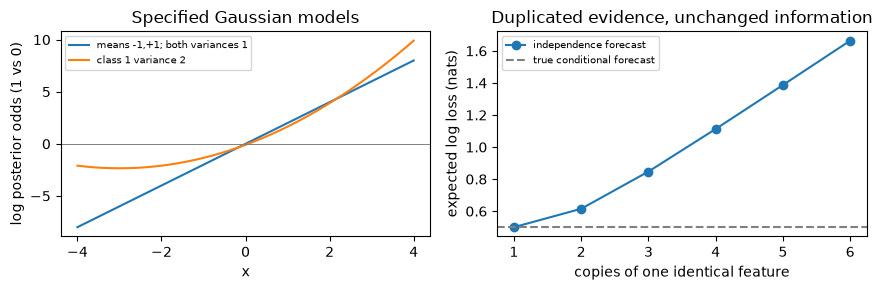

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
demo_x = np.linspace(-4, 4, 201)
demo_linear_odds = 2 * demo_x
demo_quadratic_odds = -.5*np.log(2) - (demo_x-1)**2/4 + (demo_x+1)**2/2
axes[0].plot(demo_x, demo_linear_odds, label='means -1,+1; both variances 1')
axes[0].plot(demo_x, demo_quadratic_odds, label='class 1 variance 2')
axes[0].axhline(0, color='gray', linewidth=.7)
axes[0].set(xlabel='x', ylabel='log posterior odds (1 vs 0)', title='Specified Gaussian models')
axes[0].legend(fontsize=7)
demo_copies = np.arange(1, 7)
demo_odds = demo_copies * np.log(4.)
demo_true_loss = -.8*np.log(.8) - .2*np.log(.2)
demo_factorized_loss = .8*np.logaddexp(0, -demo_odds) + .2*np.logaddexp(0, demo_odds)
axes[1].plot(demo_copies, demo_factorized_loss, 'o-', label='independence forecast')
axes[1].axhline(demo_true_loss, color='gray', linestyle='--', label='true conditional forecast')
axes[1].set(xlabel='copies of one identical feature', ylabel='expected log loss (nats)', title='Duplicated evidence, unchanged information')
axes[1].legend(fontsize=7)
fig.tight_layout(); plt.show()

### Exercise 02.03.12 — Compare covariance assumptions with matched budgets

**Type:** Experimental · **Answer:** Code

Use seeds 212–214. For each seed, generate 120 training and 200 validation rows, balanced by class and generated independently, in $d=4$. Means are $(-.5,0,0,0)$ and $(.5,0,0,0)$. In regime A both covariances equal $.4\mathbf1\mathbf1^T+.6I$; in regime B class 0 retains that covariance and class 1 uses $\operatorname{diag}(2,.5,1,1)$. Fit shared, full and diagonal models with fixed jitter $10^{-6}$. Report validation error, log loss, runtime and the declared memory layout. Do not select and report a final test winner from these validation rows.

**Expected outcome:** paired per-seed comparisons and an assumption-aware interpretation without invented superiority claims.

In [ ]:
# Your code for Exercise 02.03.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.12**

Create each split once per regime/seed and pass identical arrays to every model. Use log posteriors directly for log loss.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.12**

This depends on the Gaussian fit/predict references. The experiment varies covariance structure while controlling data and budgets. Population assumptions suggest where a model may be appropriate; the finite results still need measurement. Three seeds show a bounded sensitivity check, not a precise population confidence interval or an asymptotic result.

~~~python
from time import perf_counter

demo_gaussian_records = []
for seed in range(212, 215):
    for regime in ('shared', 'unequal'):
        rng = np.random.default_rng(seed)
        common = .4*np.ones((4,4)) + .6*np.eye(4)
        covariances = [common, common if regime == 'shared' else np.diag([2.,.5,1.,1.])]
        means = [np.array([-.5,0,0,0]), np.array([.5,0,0,0])]
        splits = []
        for per_class in (60, 100):
            X = np.vstack([rng.multivariate_normal(means[c], covariances[c], per_class) for c in (0,1)])
            y = np.repeat([0,1], per_class)
            splits.append((X, y))
        (train_X, train_y), (valid_X, valid_y) = splits
        for kind in ('shared', 'full', 'diagonal'):
            started = perf_counter()
            model = fit_gaussian_classifier(train_X, train_y, kind, jitter=1e-6)
            predicted, logp, _ = predict_gaussian_classifier(model, valid_X)
            demo_gaussian_records.append((seed, regime, kind, float(np.mean(predicted != valid_y)),
                                           float(-logp[np.arange(len(valid_y)), valid_y].mean()),
                                           perf_counter()-started, model['covariance'].nbytes))
assert len(demo_gaussian_records) == 18
print('Measured Gaussian validation records:', demo_gaussian_records)
~~~

</details>

### Exercise 02.03.13 — Measure dependence without changing the task

**Type:** Experimental · **Answer:** Code

Build the exact toy population with $P(Y=1)=.5$ and $P(B=1\mid Y=1)=.8$, $P(B=1\mid Y=0)=.2$. Duplicate $B$ between one and six times and compare the independence-model forecast to the true posterior. Compute exact expected log loss and classification error by enumerating the four $(Y,B)$ events; optionally add a seeded sample as a separate Monte Carlo check. Explain why more feature columns need not add information.

**Expected outcome:** unchanged optimal error $.2$, unchanged true entropy, worsening factorized log loss, and explicit exact-versus-sampled labels.

In [ ]:
# Your code for Exercise 02.03.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.13**

The four joint masses are $.4,.1,.1,.4$. A positive observation has posterior odds 4; the duplicated model raises these odds to the number of copies.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.13**

Enumeration removes sampling ambiguity for this small model. For each copy count, the independence decision equals $B$, so the error is $.2$. Its confidence departs from the true posterior, increasing expected log loss. This is a misspecification example, not evidence that Naive Bayes always performs poorly on correlated real data.

~~~python
demo_dependence = []
for copies in range(1, 7):
    loss, error = 0., 0.
    for y in (0,1):
        positive = .8 if y == 1 else .2
        for observed in (0,1):
            mass = .5 * (positive if observed else 1-positive)
            odds = copies * (np.log(4.) if observed else -np.log(4.))
            loss += mass * np.logaddexp(0, -odds if y else odds)
            error += mass * ((odds > 0) != y)
    demo_dependence.append((copies, loss, error))
assert np.allclose([row[2] for row in demo_dependence], .2)
assert np.all(np.diff([row[1] for row in demo_dependence]) > 0)
~~~

</details>

## 7. Interpretation and critical analysis

Probability quality, classification error, and feature fit answer different questions. A diagonal Gaussian can reduce estimation variance by discarding covariance parameters, but it can lose a meaningful correlated direction. A full covariance can fit spurious directions in a small sample. Correct log-domain arithmetic prevents a numerical failure; it does not validate either assumption. Evaluate both proper probability loss and the decision metric needed for the application.

### Bounded primary-source study

Read [CS229 Generative Learning Algorithms, §§1.2–1.3](https://cs229.stanford.edu/summer2020/cs229-notes2.pdf) after this chapter. The selected scope is shared-covariance Gaussian estimation and its relationship to a logistic posterior; the lesson's explanations, numerical examples, and exercises are original. Translate the source's binary notation into $(n,d)$ arrays and audit one equation. Do not treat broad comparative prose as a guarantee for your finite dataset.

### Exercise 02.03.14 — Test the scope of a generative-versus-discriminative claim

**Type:** Critical · **Answer:** Markdown

Using the selected reading, write a short evidence table: source equation or section, assumptions, your independently expanded log odds, and a bounded claim supported by a local check. Give a non-Gaussian feature model with logistic posterior odds. Explain why identical posterior function families do not imply identical fitted estimators or finite-sample performance.

**Expected outcome:** a concrete primary-source connection, one independently checked equation, and separated modeling, estimation and experimental claims.

**Your response to Exercise 02.03.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.14**

For a binary class with Poisson feature models having rates $\lambda_0,\lambda_1>0$, expand the log-likelihood ratio of one nonnegative integer count. The feature itself is a count, not binary.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.14**

For scalar count $x$, two Poisson conditionals give log odds $x\log(\lambda_1/\lambda_0)-(\lambda_1-\lambda_0)+\log(\pi_1/\pi_0)$: affine in $x$ without Gaussian features. The Gaussian shared-covariance expansion is another sufficient construction of logistic posteriors. Neither construction is necessary. Joint-likelihood fitting allocates modeling effort to $p(x\mid y)$ and priors; conditional fitting optimizes a different objective. A hand identity establishes the algebra, and a finite comparison establishes only the stated dataset/split/budget result. It cannot prove universal robustness or superiority. Use the repository's paper-study template to record the distinction.

</details>

### Exercise 02.03.15 — Diagnose shift, vocabulary decisions and calibration

**Type:** Critical · **Answer:** Markdown

A text classifier was validated on short documents, receives much longer documents with repeated synonymous features, and predicts probabilities near zero or one. Propose a bounded diagnosis covering length, unknown-token fraction, class-prior shift and conditional dependence. Explain when replacing priors is justified and which held-out observations must stay unused.

**Expected outcome:** controlled checks, at least one competing explanation, and an honest limit on a prior-correction argument.

**Your response to Exercise 02.03.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.15**

Replacing $\pi_c$ assumes the class-conditionals remain valid. Stronger posterior odds can be an artifact of duplicated evidence.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.15**

Record document length and unknown fraction using the frozen training vocabulary; compare proper losses and reliability on a separate diagnostic validation sample. Stratify by length with adequate counts, and compare presence versus count features with matched splits. A known pure prior shift can be modeled by replacing class priors while holding class-conditionals fixed; arbitrary vocabulary or conditional shifts violate that argument. Longer documents also increase repeated log evidence in the count model, and correlated terms can exaggerate confidence. Candidate recalibration or smoothing decisions require training/internal validation; repeatedly inspecting the final test set invalidates its role. Report small-subgroup uncertainty and avoid treating a normalized maximum posterior as an out-of-distribution detector.

</details>

## 8. Review questions and knowledge checks

Answer these without opening the references. The goal is to explain, implement, verify and evaluate a likelihood model, including its omissions. A correct final class label alone is insufficient evidence.

### Exercise 02.03.16 — Audit underflow and model-dependent empty inputs

**Type:** Numerical · **Answer:** Markdown

Evaluate $0.5^{2000}$ in ordinary double precision and its log. For a two-class model with equal priors and Bernoulli feature probabilities $\theta_0=(.8,.8)$, $\theta_1=(.2,.2)$, compute the posterior for an all-zero row. Compare an empty multinomial document with equal priors. Explain why clipping a zero product to a tiny constant does not recover the missing evidence.

**Expected outcome:** underflow with finite log $-2000\log2$, Bernoulli posterior $p(0)=1/17$, and multinomial posterior $(.5,.5)$.

**Your response to Exercise 02.03.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.16**

Absent Bernoulli features still have probabilities $1-\theta_{cj}$. No tokens means a zero count dot product.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.16**

The direct product underflows to zero, while its log is approximately $-1386.294361$. The all-absent Bernoulli likelihoods are $.2^2$ and $.8^2$, giving class-0 posterior $1/17$. With no tokens the multinomial score is only the class log prior, so equal priors remain equal. Replacing underflowed products by a common floor discards differences in log evidence and can invent ties or incorrect confidence. Log-domain accumulation retains those differences within representable range.

</details>

### Exercise 02.03.17 — State a mastery gate and remaining uncertainty

**Type:** Conceptual · **Answer:** Markdown

Explain the difference between shared, full and diagonal Gaussian covariance; conditional and marginal independence; Bernoulli and multinomial observations; MLE covariance and unbiased covariance; and posterior-predictive smoothing and MAP. Name one independent numerical check, one controlled evaluation, and one limitation that remains after both pass.

**Expected outcome:** a concise oral/written explanation and pointers to actual learner evidence rather than a reading checklist.

**Your response to Exercise 02.03.17**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.03.17**

Give the array shape or denominator for each distinction, then name a failure case outside the tested assumptions.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.03.17**

Shared covariance ties class geometry; full gives each class a symmetric covariance; diagonal gives class-specific variances and conditional independence in a Gaussian model. Marginal dependence can arise from a common class even with conditional independence. Bernoulli encodes presence and absence per document, whereas multinomial encodes counts given length. MLE uses within-class divisors $n_c$ or pooled $n$; unbiased scatter corrections answer a different estimation question. Additive feature smoothing here uses posterior means/predictive feature probabilities, not prior modes. Independent scalar densities, expanded odds and finite-difference derivatives validate particular numerical contracts. Matched validation compares chosen models for a declared distribution and budget. Neither passing checks nor high accuracy validates arbitrary distribution shifts or every probability forecast.

</details>

## 9. Summary and next learning steps

You connected class-conditional likelihoods to posterior decisions, covariance assumptions to boundary geometry, and factorized evidence to confidence failure. Keep Gaussian density normalization, covariance divisors, log-domain calculations, smoothing semantics and train-only feature construction explicit. The small models make assumptions inspectable before later latent-variable and language models introduce more complex parameterizations.

Before advancing, produce your own derivation, manually implemented models, independent value/gradient checks, and a measured comparison with limitations. Retain the original data split and resource record. Next: decision trees, where expected-loss reduction determines a local split and validation controls tree complexity. Return to the [stage guide](README.md) or the [full learning path](../../README.md); units marked planned are not yet authored.